In [94]:
%env CUDA_VISIBLE_DEVICES=1
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
import os
import torch

env: CUDA_VISIBLE_DEVICES=1
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
from ne_aligned_utils.plot import plot_aligned_embedding

ModuleNotFoundError: No module named 'ne_aligned'

In [454]:
import cne

In [455]:
fig_path = "/gpfs01/berens/user/sdamrich/data/ne_aligned_utils/figures"

In [456]:
# first dataset: circle with noise
n = 400
theta = np.linspace(0, 2 * np.pi, n)
x1 = np.cos(theta) + 0.1 * np.random.randn(n)
x2 = np.sin(theta) + 0.1 * np.random.randn(n)
x = np.stack([x1, x2], axis=1)


# second dataset: square with four sides and noise
n_side = n // 4 //2
x1_side1 = np.linspace(-1, 1, n_side) + 0.1 * np.random.randn(n_side)
x2_side1 = -1 + 0.1 * np.random.randn(n_side)
x1_side2 = 1 + 0.1 * np.random.randn(n_side)
x2_side2 = np.linspace(-1, 1, n_side) + 0.1 * np.random.randn(n_side)
x1_side3 = np.linspace(1, -1, n_side) + 0.1 * np.random.randn(n_side)
x2_side3 = 1 + 0.1 * np.random.randn(n_side)
x1_side4 = -1 + 0.1 * np.random.randn(n_side)
x2_side4 = np.linspace(1, -1, n_side) + 0.1 * np.random.randn(n_side)
x_square = np.concatenate([
    np.stack([x1_side1, x2_side1], axis=1),
    np.stack([x1_side2, x2_side2], axis=1),
    np.stack([x1_side3, x2_side3], axis=1),
    np.stack([x1_side4, x2_side4], axis=1),
], axis=0)

x_square *= 0.3


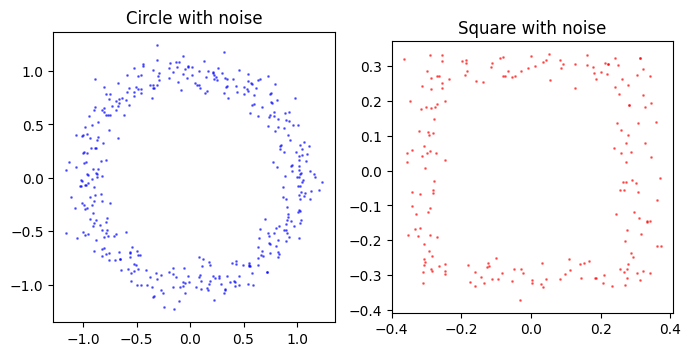

In [457]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].scatter(x[:, 0], x[:, 1], s=1.0, color="blue", alpha=0.5)
ax[0].set_title("Circle with noise")
ax[0].set_aspect("equal")
#ax[0].axis("off")
ax[1].scatter(x_square[:, 0], x_square[:, 1], s=1.0, color="red", alpha=0.5)
ax[1].set_title("Square with noise")
ax[1].set_aspect("equal")
#ax[1].axis("off")


In [458]:
# kNNs from other dataset
from sklearn.neighbors import NearestNeighbors
k = 15

nbrs_circle = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(x_square)
_, indices_circle = nbrs_circle.kneighbors(x)

nbrs_square = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(x)
_, indices_square = nbrs_square.kneighbors(x_square)


In [459]:
indices_circle.shape

(400, 15)

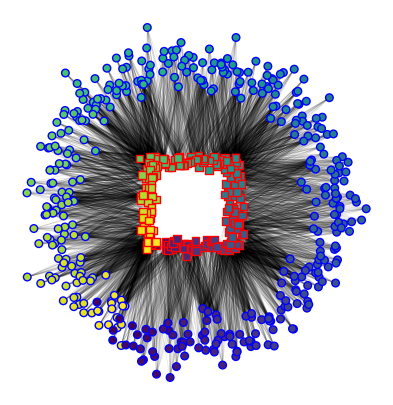

In [460]:
fig, ax = plt.subplots(figsize=(5,5))
ax.scatter(x[:, 0],
           x[:, 1],
           s=30.0,
           facecolors=plt.cm.viridis(((np.arange(len(x)) - len(x)/1.5) % len(x))/len(x)),
           edgecolors="blue",
           linewidth=1,
           marker="o",
           alpha=1,
           zorder=10)
ax.scatter(x_square[:, 0],
           x_square[:, 1],
           s=30.0,
           facecolors=plt.cm.viridis(np.linspace(0, 1, len(x_square))),
           edgecolor="red",
           linewidth=1,
           marker="s",
           alpha=1,
           zorder=10)

for i in range(0, x.shape[0], 1):
    for j in indices_circle[i]:
        ax.plot([x[i, 0], x_square[j, 0]], [x[i, 1], x_square[j, 1]], color="k", alpha=0.1, linewidth=0.5)
for i in range(0, x_square.shape[0], 1):
    for j in indices_square[i]:
        ax.plot([x_square[i, 0], x[j, 0]], [x_square[i, 1], x[j, 1]], color="k", alpha=0.1, linewidth=0.5)
ax.set_aspect("equal")
ax.axis("off")

fig.savefig(os.path.join(fig_path, "alignment_example_data.png"), dpi=300)

In [461]:
from scipy.sparse import coo_matrix
rows = np.concatenate([np.arange(x.shape[0]).repeat(k), np.arange(x_square.shape[0]).repeat(k) + x.shape[0]])
cols = np.concatenate([indices_circle.flatten() + x.shape[0], indices_square.flatten()])

graph = coo_matrix((np.ones_like(rows), (rows, cols)), shape=(x.shape[0] + x_square.shape[0], x.shape[0] + x_square.shape[0]))

In [473]:
embedder = cne.CNE(negative_samples=5, batch_size=2048, embd_dim=2, n_epochs=400, metric="euclidean", loss_mode="infonce", alignment=True, data_on_gpu="True", sample_pos=None)

In [474]:
data = np.concatenate([x, x_square], axis=0)
embd = embedder.fit_transform(data, graph=graph)

Finished epoch 0/400, loss 4208.489
Finished epoch 80/400, loss 2990.949
Finished epoch 160/400, loss 1306.398
Finished epoch 240/400, loss 1250.239
Finished epoch 320/400, loss 1223.829


(np.float64(-13.592857808758563),
 np.float64(13.345637708973268),
 np.float64(-13.32276337572063),
 np.float64(12.481563162093272))

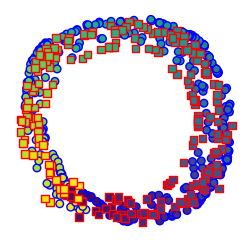

In [475]:
fig, ax = plt.subplots(figsize=(3,3))
ax.scatter(*embd[:x.shape[0]].T,
           s=30.0,
           facecolors=plt.cm.viridis(((np.arange(len(x)) - len(x)/1.5) % len(x))/len(x)),
           edgecolors="blue",
           linewidth=1,
           marker="o",
           alpha=1,
           zorder=10)
ax.scatter(*embd[x.shape[0]:].T,
           s=30.0,
           facecolors=plt.cm.viridis(np.linspace(0, 1, len(x_square))),
           edgecolor="red",
           linewidth=1,
           marker="s",
           alpha=1,
           zorder=10)
ax.set_aspect("equal")
ax.axis("off")
#fig.savefig(os.path.join(fig_path, "alignment_example_embd.png"), dpi=300)

In [26]:
# OT variant

In [27]:
import ot

In [56]:
cost.shape

(400, 200)

In [57]:
print(cost[:5, :5])

[[171.50150382 172.71293092 170.78196038 172.87186835 172.31662997]
 [172.32691995 173.53960466 171.60821643 173.69128313 173.1379558 ]
 [170.23548559 171.44272798 169.51815666 171.60243745 171.04866868]
 [163.84032453 165.02006467 163.14381079 165.15562237 164.62129715]
 [165.59680393 166.78297993 164.8963462  166.91986235 166.38243586]]


In [58]:
cost = ot.dist(x, x_square+ 10)
a = np.ones((x.shape[0],)) / x.shape[0]
b = np.ones((x_square.shape[0],)) / x_square.shape[0]
eps = np.median(cost)
P = ot.sinkhorn(a, b, cost, reg=eps/500)


In [60]:
eps

np.float64(200.57609058390312)

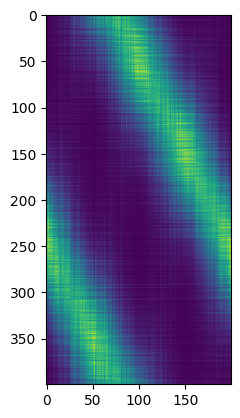

In [75]:
plt.imshow(P)

In [73]:
np.sort(P[0])
#>> have to decrease eps a lot to make it fairly sparse. Need to set quite a bit to zero. This I can do also for stronger regularization.

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

(array([   46.,   706.,  3133.,  7479., 10954., 10166.,  8741.,  8499.,
         9965., 20311.]),
 array([-205.8350183 , -185.94094793, -166.04687757, -146.1528072 ,
        -126.25873684, -106.36466647,  -86.47059611,  -66.57652574,
         -46.68245537,  -26.78838501,   -6.89431464]),
 <BarContainer object of 10 artists>)

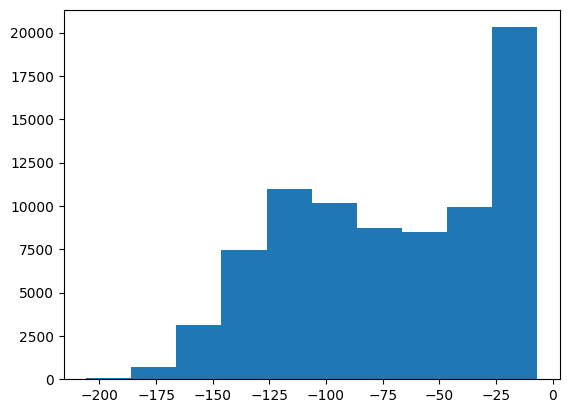

In [54]:
plt.hist(np.log(P.flatten()))

# Fig 1 data

In [689]:
import numpy as np

# Parameters
n0 = int(1e3) //10
n1 = int(5e3) //10
tol = 1e-12
maxIter = int(1e4)


seed = 0



In [690]:
from src.ne_aligned_utils import make_fig1_data

In [691]:
fig1_data = make_fig1_data(n0=n0, n1=n1, seed=seed)

In [692]:
fig1_data[0].shape

(100, 3)

In [693]:
dist = ot.dist(fig1_data[0], fig1_data[1]) # this is already the squared Euclidean distance
eps = np.median(dist) # square of median and median of squares are the same

a = np.ones((n0,)) / n0
b = np.ones((n1,)) / n1

In [694]:
dist.shape

(100, 500)

In [695]:
eps

np.float64(14.822250001188598)

In [696]:
P = ot.sinkhorn(a, b, dist, reg=eps/100, numItermax=maxIter, stopThr=tol)


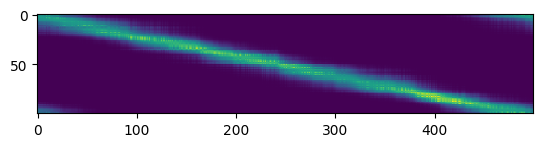

In [697]:
plt.imshow(P)

In [698]:
P.sum(0)

array([0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
       0.002, 0.002,

In [699]:
P.max()

np.float64(0.00021916258605962722)

(array([  11.,   23.,   52.,   95.,  148.,  217.,  317.,  488.,  572.,
         717.,  883.,  974., 1123., 1171., 1266., 1353., 1263., 1274.,
        1293., 1184., 1183., 1056., 1005.,  966.,  944.,  946.,  918.,
         897.,  869.,  897.,  908.,  874.,  886.,  815.,  828.,  898.,
         908.,  905.,  950.,  969., 1051., 1104., 1150., 1214., 1368.,
        1475., 1697., 2314., 4182., 1399.]),
 array([-32.2292187 , -31.75314826, -31.27707782, -30.80100738,
        -30.32493694, -29.8488665 , -29.37279606, -28.89672562,
        -28.42065518, -27.94458474, -27.4685143 , -26.99244386,
        -26.51637342, -26.04030298, -25.56423254, -25.0881621 ,
        -24.61209166, -24.13602122, -23.65995078, -23.18388034,
        -22.7078099 , -22.23173946, -21.75566902, -21.27959858,
        -20.80352814, -20.3274577 , -19.85138726, -19.37531682,
        -18.89924638, -18.42317594, -17.9471055 , -17.47103506,
        -16.99496462, -16.51889418, -16.04282374, -15.5667533 ,
        -15.09068286, -1

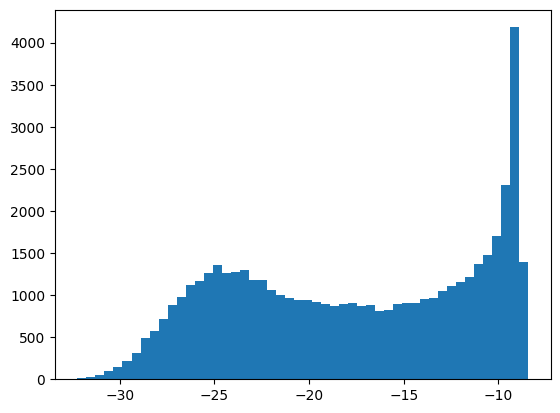

In [700]:
plt.hist(np.log(P.flatten()), bins=50)

(0.0, 0.011000000000000008)

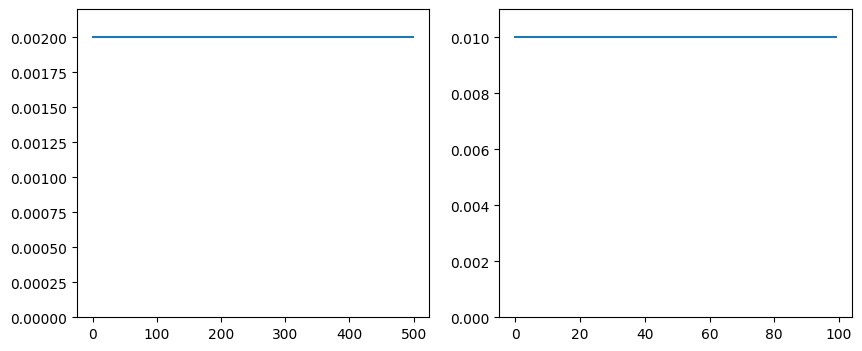

In [701]:
plan = P
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(plan.sum(0))
ax[0].set_ylim(0, 1.1*max(plan.sum(0)))

ax[1].plot(plan.sum(1))
ax[1].set_ylim(0, 1.1*max(plan.sum(1)))

In [702]:
k = 15

P_sparse = np.zeros_like(P)
for i in range(P.shape[0]):
    idx = np.argpartition(P[i], -k)[-k:]
    P_sparse[i, idx] = 1

for j in range(P.shape[1]):
    idx = np.argpartition(P[:, j], -k)[-k:]
    P_sparse[idx, j] = 1

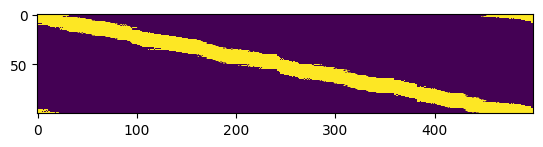

In [703]:
plt.imshow(P_sparse)

(0.0, 102.30000000000001)

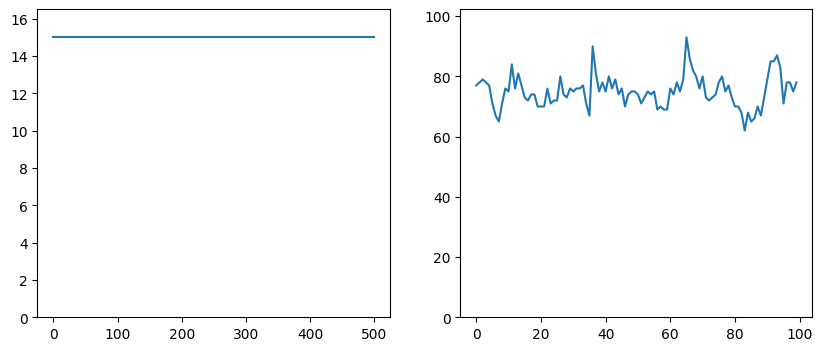

In [704]:
plan = P_sparse
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(plan.sum(0))
ax[0].set_ylim(0, 1.1*max(plan.sum(0)))

ax[1].plot(plan.sum(1))
ax[1].set_ylim(0, 1.1*max(plan.sum(1)))

In [705]:
# set only close to zero values to zero
P_half_sparse = P * P_sparse

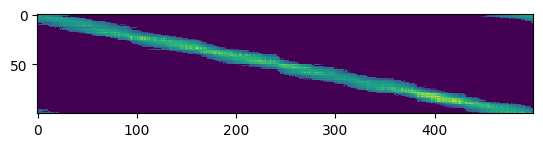

In [706]:
plt.imshow(P_half_sparse)

(0.0, 0.009953445373744017)

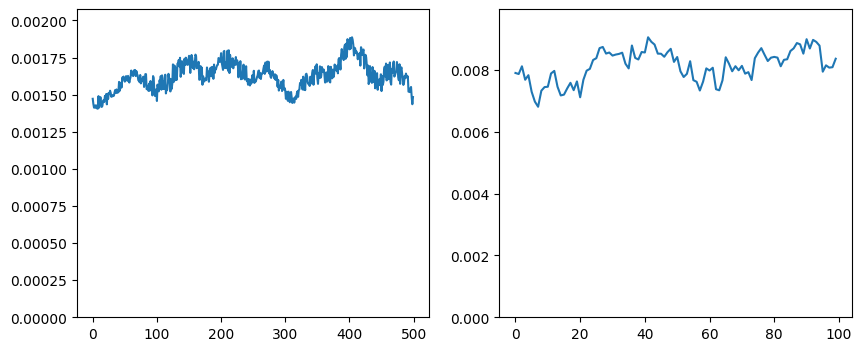

In [707]:
plan = P_half_sparse
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(plan.sum(0))
ax[0].set_ylim(0, 1.1*max(plan.sum(0)))

ax[1].plot(plan.sum(1))
ax[1].set_ylim(0, 1.1*max(plan.sum(1)))

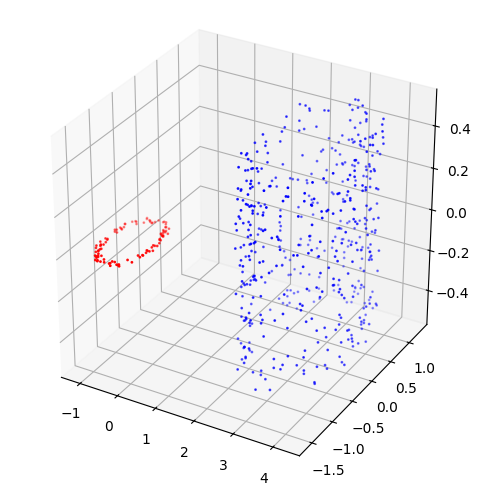

In [736]:
# plot in 3d
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(*fig1_data[0].T, c='r', s=1)
ax.scatter(*fig1_data[1].T, c='b', s=1)
ax.set_box_aspect([1,1,1])  # Equal aspect ratio

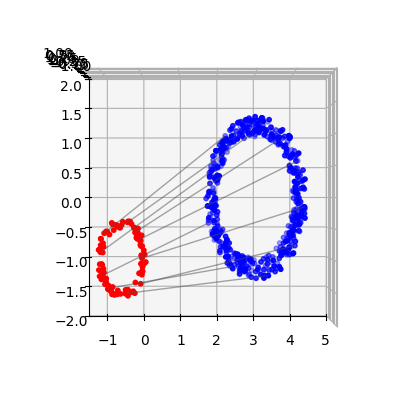

In [737]:
from mpl_toolkits.mplot3d.art3d import Line3DCollection
%matplotlib inline
# Indices of max partner per row / column
idx_row = P.argmax(axis=1)[::10]       # for each i in X1 -> best j in X2
idx_col = P.argmax(axis=0)[::10]        # for each j in X2 -> best i in X1

# Build line segments
segs_row = np.stack([fig1_data[0][::10]  ,fig1_data[1][idx_row]], axis=1)           # (n1, 2, 3)
segs_col = np.stack([fig1_data[1][::10]  , fig1_data[0][idx_col]], axis=1)           # (n1, 2, 3)

# Plot
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(*fig1_data[0].T, s=10, c='r', zorder=10)  # source cloud
ax.scatter(*fig1_data[1].T, s=10, c='b', zorder=10)  # target cloud

# Add semi-transparent line collections
lc1 = Line3DCollection(segs_row, colors=(0.3, 0.3, 0.3, 0.5), linewidths=1.0)
#lc2 = Line3DCollection(segs_col, colors=(0.3, 0.3, 0.3, 0.5), linewidths=1.0)
ax.add_collection3d(lc1)
#ax.add_collection3d(lc2)

# Match MATLAB view/limits and hide axes
ax.set_xlim(-1.5, 5)
ax.set_ylim(-2, 2)
ax.set_zlim(-1, 1)
#ax.set_box_aspect((6.5, 4, 2))   # keep proportions reasonable
#ax.set_axis_off()
ax.view_init(elev=90, azim=-90)

In [655]:
data =  np.concatenate(fig1_data, axis=0)
init = np.random.randn(fig1_data[0].shape[0] + fig1_data[1].shape[0], 2) * 2

In [657]:
B_sparse = get_bipartite_graph(P_sparse)

In [658]:
print(B_sparse.shape)
print(B_sparse.nnz)

(6000, 6000)
159990


In [659]:
np.log2(6000*15)

np.float64(16.457637380991763)

In [660]:
embedder = cne.CNE(negative_samples=50, batch_size=2**14, embd_dim=2, n_epochs=1000, metric="euclidean", loss_mode="infonce", alignment=True, data_on_gpu=True, sample_pos=None)
embd = embedder.fit_transform(data, graph=B_sparse, init=init)

Finished epoch 0/1000, loss 43591.974
Finished epoch 200/1000, loss 32061.882
Finished epoch 400/1000, loss 18722.976
Finished epoch 600/1000, loss 17523.885
Finished epoch 800/1000, loss 16883.771


In [662]:
cmap = plt.get_cmap("viridis")


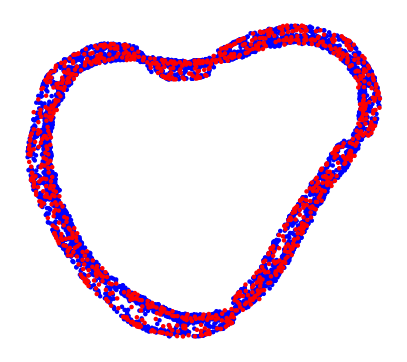

In [663]:
#colors =  ["r"]*n0 + [cmap(fig1_data[1][i, 2] + 0.5) for i in range(n1)]
colors =  ["r"]*n0 + ["b"]*n1
seed = 2
fig = plot_aligned_embedding(embd[::-1],
                             fig1_data[0].shape[0],
                             color =colors[::-1],
                             fig_name=os.path.join(fig_path, "alignment_example_fig1_dense.png"),
                             shuffle=False,
                             seed=seed)

In [664]:
from sklearn.neighbors import NearestNeighbors


def compute_concordance(x, y, k=50):
    """
    Computes the concordance metric between two datasets x and y. The concordance is defined as the share of k nearest neighbors of each point in x that are also among the k nearest neighbors of the corresponding point in y.
    :param x: array of positions for first dataset
    :param y: array of positions for second dataset
    :param k: number of nearest neighbors considered
    :return: Share of x's k nearest neighbors that are also y's k nearest neighbors
    """
    assert x.shape[0] == y.shape[0], "x and y must have the same number of points"
    nbrs_x = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(x)
    _, indices_x = nbrs_x.kneighbors(x)
    nbrs_y = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(y)
    _, indices_y = nbrs_y.kneighbors(y)

    # create sparse knn graph matrices
    n = x.shape[0]
    data = np.ones(n * k)
    knn_graphs = []
    rows = np.arange(n).repeat(k)
    for indices in [indices_x, indices_y]:
        cols = indices.flatten()
        knn_graphs.append(coo_matrix((data, (rows, cols)), shape=(n, n)))

    intersection = knn_graphs[0].multiply(knn_graphs[1])
    intersection = np.array(intersection.sum(1)).flatten()

    union = knn_graphs[0].maximum(knn_graphs[1])
    union = np.array(union.sum(1)).flatten()
    union[union == 0] = 1  # avoid division by zero

    concordance = intersection / union
    return concordance.mean()

In [665]:
fig1_data_clean0 = fig1_data[0][:, :2] + np.array([0.5, 1])
fig1_data_clean1 = fig1_data[1][:, :2] + np.array([-3, 0])
fig1_data_clean = np.concatenate([fig1_data_clean0, fig1_data_clean1], axis=0)

In [666]:
concordance = compute_concordance(fig1_data_clean, embd, k=50)

In [667]:
concordance

np.float64(0.38415262142245077)

In [668]:
U, S, V  = np.linalg.svd(P, full_matrices=False)

In [669]:
U.shape

(1000, 1000)

In [670]:
V.shape

(1000, 5000)

In [671]:
embd_le = np.concatenate([U[:, 1:3]*np.sqrt(n0), V.T[:, 1:3]*np.sqrt(n1)], axis=0)

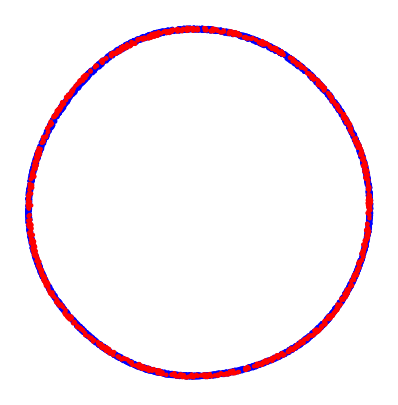

In [672]:
colors =  ["r"]*n0 + ["b"]*n1
seed = 2
fig = plot_aligned_embedding(embd_le[::-1],
                             fig1_data[0].shape[0],
                             color =colors[::-1],
                             #fig_name=os.path.join(fig_path, "alignment_example_fig1_dense.png"),
                             shuffle=False,
                             seed=seed)

In [673]:
concordance_le = compute_concordance(fig1_data_clean, embd_le, k=50)

In [674]:
concordance_le

np.float64(0.24694897633101554)

# within data set repulsion

In [708]:
data =  np.concatenate(fig1_data, axis=0)
init = np.random.randn(fig1_data[0].shape[0] + fig1_data[1].shape[0], 2) * 2

In [709]:
B_sparse = get_bipartite_graph(P_sparse)

In [746]:
embedder = cne.CNE(negative_samples=5, batch_size=2**14, embd_dim=2, n_epochs=100, metric="euclidean", loss_mode="nce", alignment=True, data_on_gpu=True, sample_pos=None)
embd = embedder.fit_transform(data, graph=B_sparse, init=init)

Finished epoch 0/100, loss 124592.355
Finished epoch 20/100, loss 125787.991
Finished epoch 40/100, loss 115380.948
Finished epoch 60/100, loss 101391.751
Finished epoch 80/100, loss 83620.091


(np.float64(-1.753105152411669),
 np.float64(1.4636884131793113),
 np.float64(-2.355443085508861),
 np.float64(2.460665376670696))

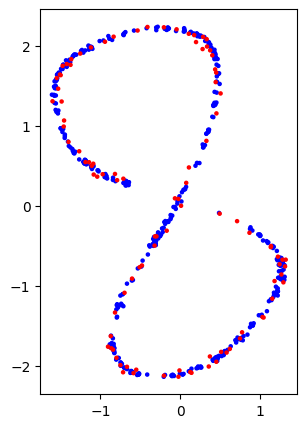

In [747]:
colors =  ["r"]*n0 + ["b"]*n1
seed = 2
fig = plot_aligned_embedding(embd[::-1],
                             fig1_data[0].shape[0],
                             color =colors[::-1],
                             #fig_name=os.path.join(fig_path, "alignment_example_fig1_dense.png"),
                             shuffle=False,
                             seed=seed)
ax = fig.get_axes()[0]
ax.axis("on")

In [688]:
embedder.cne.alignment

True

In [680]:
concordance = compute_concordance(fig1_data_clean, embd, k=50)

In [681]:
print(concordance)

0.3822632123599809


In [729]:
from cne.cne import make_neighbor_indices

alignment = True
negative_samples = 5
batch_size = 10
neigh_idx = make_neighbor_indices(batch_size, negative_samples, alignment=alignment, device="cpu")

In [730]:
print(neigh_idx % (2*batch_size))

tensor([[10, 15, 13, 11, 13, 18],
        [11, 16, 16, 15, 18, 18],
        [12, 12, 17, 15, 12, 14],
        [13, 16, 17, 13, 11, 16],
        [14, 16, 11, 11, 17, 14],
        [15, 18, 11, 11, 17, 17],
        [16, 11, 17, 17, 17, 15],
        [17, 14, 15, 12, 13, 14],
        [18, 16, 14, 13, 13, 10],
        [19, 11, 13, 12, 17, 17],
        [ 0,  3,  4,  0,  7,  8],
        [ 1,  1,  8,  5,  2,  2],
        [ 2,  1,  8,  5,  2,  8],
        [ 3,  3,  3,  6,  4,  4],
        [ 4,  3,  1,  2,  3,  6],
        [ 5,  3,  4,  5,  7,  1],
        [ 6,  0,  0,  6,  0,  6],
        [ 7,  8,  2,  5,  2,  3],
        [ 8,  8,  5,  0,  3,  8],
        [ 9,  7,  2,  4,  3,  5]])
